# DC electro-optical modulation with a 2D charge solver

This tutorial repeats the DC electro-optical analysis of the [DC electro-optical modulation](../dc_electro_optical/dc_electro_optical.ipynb) tutorial with the Lumerical solvers:

- the optical modes come from the FDE solver of Lumerical MODE (`OpticalSimulatorMODE`) instead of femwell,
- the 1D Poisson-drift-diffusion solve along a line is replaced by a full 2D drift-diffusion solve of the cross-section in Lumerical CHARGE (`ChargeSimulatorCHARGE`).

<div style="text-align: center;">
  <img src="support/main.png" alt="InP electro-optic phase modulator cross-section" style="max-width: 80%; height: auto;">
</div>

The 1D solvers (`ChargeSimulatorSolcore`, `ChargeSimulatorNN`) solve the junction along one line and copy that profile sideways over the semiconductor polygons. That works well for wide vertical pin junctions. A 2D solve also captures what the 1D approximation leaves out:

- the lateral current path through the n-layer to the side contact,
- field fringing and depletion at the edges of the deep-etched waveguide,
- the real contact geometry and the insulators around the mesa.

The workflow is unchanged: optical solve → `transfer_results_to_device` → charge solve → `transfer_results_to_device` → `ElectroOpticalSimulator`. Because the solvers are coupled only through the `PhotonicDevice`, the `ElectroOpticalSimulator` part is identical to the 1D tutorial.

> **Note:** this tutorial needs a licensed Ansys Lumerical installation with MODE and DEVICE (CHARGE), and the path to `lumapi.py` set under `lumerical_api: path:` in imodulator's `config.yaml`.

We use the same `InP_EOPM` device as in the 1D tutorial. The only difference is in the `charge_transport_simulator_kwargs` of the semiconductor polygons. `ChargeSimulatorCHARGE` reads:

- `doping_type`: `"n"` or `"p"`. Polygons without a `doping_type` are not part of the charge simulation (here the substrate).
- `doping_conc`: doping concentration in cm$^{-3}$.
- `sol_obp_material`: the `openbandparams` material that sets the band gap, electron affinity, density-of-states masses and DC permittivity. These are the same parameters `ChargeSimulatorSolcore` uses. If it is missing, GaInPAs lattice-matched to InP at `alloy_y` is used.
- `alloy_y`: the As fraction used to compute the (constant) electron and hole mobilities from the `imodulator.utils` InGaAsP models.

CHARGE has no InGaAsP material model, so each layer is built on CHARGE's InP model with these parameters overridden.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import imodulator
import shapely
import openbandparams as obp
from imodulator.ElectroOpticalModel import InGaAsPElectroOpticalModel
from imodulator.ChargeSimulator import ChargeSimulatorCHARGE
from imodulator.ElectroOpticalSimulator import ElectroOpticalSimulator
from imodulator.OpticalSimulator import OpticalSimulatorMODE

%matplotlib inline


def tand_fitted_bcb(x):
    """
    Fitted to results from https://link.springer.com/article/10.1007/s10762-009-9552-0

    x must be in GHz
    """
    out = 0.0093839 - 0.01790336 * np.exp(-0.04773444 * (x - -4.64170761))

    if isinstance(x, (list, np.ndarray)):
        x = np.asarray(x)

        out[np.where(out < 0.001)] = 0.001
    else:
        if out < 0.001:
            out = 0.001
    return out


class InP_EOPM:
    def __init__(self, **kwargs):

        self.e = 1.60e-19  # electron charge in C
        self.e0 = 8.85e-12  # vacuum permittivity in F/m

        self.w_sig_metal = 5  # Width of signal metal in um
        self.metal_sep = 10  # Separation between signal and ground metals in um
        self.h_metal = 4  # Height of metals in um
        self.w_gnd_metal = 10

        self.w_wg = 1
        self.h_n = 0.4
        self.h_wg1 = 0.5
        self.h_wg2 = 0.3
        self.h_p1 = 1
        self.h_p2 = 0.2

        self.h_box = 4

        self.w_window = 100
        self.h_bottom = 30
        self.h_top = 30

        for kwarg, value in kwargs.items():
            if hasattr(self, kwarg):
                setattr(self, kwarg, value)

    def _make_meshes(self):
        # optical mesh
        self.optical_mesh_settings = {
            "substrate": {"resolution": 0.5, "SizeMax": 5, "distance": 0.1},
            "background": {"resolution": 0.5, "SizeMax": 5, "distance": 0.1},
            "box": {"resolution": 0.3, "SizeMax": 0.2, "distance": 0.1},
            "sig_metal": {"resolution": 10, "SizeMax": 0.2, "distance": 0.1},
            "n_metal_left": {"resolution": 10, "SizeMax": 0.2, "distance": 0.1},
            "n_metal_right": {"resolution": 10, "SizeMax": 0.2, "distance": 0.1},
            "bcb": {"resolution": 0.5, "SizeMax": 5, "distance": 0.1},
            "n": {"resolution": 0.5, "SizeMax": 5, "distance": 0.1},
            "wg1": {"resolution": 0.1, "SizeMax": 5, "distance": 0.1},
            "wg2": {"resolution": 0.1, "SizeMax": 5, "distance": 0.1},
            "p1": {"resolution": 0.5, "SizeMax": 5, "distance": 0.1},
            "p2": {"resolution": 0.5, "SizeMax": 5, "distance": 0.1},
        }

        # RF mesh
        self.rf_mesh_settings = {
            "substrate": {"resolution": 5, "SizeMax": 5, "distance": 0.1},
            "background": {"resolution": 5, "SizeMax": 5, "distance": 0.1},
            "box": {"resolution": 3, "SizeMax": 3, "distance": 0.1},
            "sig_metal": {"resolution": 3, "SizeMax": 3, "distance": 0.1},
            "n_metal_left": {"resolution": 3, "SizeMax": 3, "distance": 0.1},
            "n_metal_right": {"resolution": 3, "SizeMax": 3, "distance": 0.1},
            "bcb": {"resolution": 5, "SizeMax": 5, "distance": 0.1},
            "n": {"resolution": 5, "SizeMax": 5, "distance": 0.1},
            "wg1": {"resolution": 1, "SizeMax": 5, "distance": 0.1},
            "wg2": {"resolution": 1, "SizeMax": 5, "distance": 0.1},
            "p1": {"resolution": 5, "SizeMax": 5, "distance": 0.1},
            "p2": {"resolution": 5, "SizeMax": 5, "distance": 0.1},
        }

        # eo mesh
        self.eo_mesh_settings = {
            "substrate": {"resolution": 0.5, "SizeMax": 5, "distance": 0.1},
            "background": {"resolution": 0.5, "SizeMax": 5, "distance": 0.1},
            "box": {"resolution": 0.3, "SizeMax": 0.2, "distance": 0.1},
            "sig_metal": {"resolution": 10, "SizeMax": 0.2, "distance": 0.1},
            "n_metal_left": {"resolution": 10, "SizeMax": 0.2, "distance": 0.1},
            "n_metal_right": {"resolution": 10, "SizeMax": 0.2, "distance": 0.1},
            "bcb": {"resolution": 0.5, "SizeMax": 5, "distance": 0.1},
            "n": {"resolution": 0.1, "SizeMax": 5, "distance": 0.1},
            "wg1": {"resolution": 0.05, "SizeMax": 5, "distance": 0.1},
            "wg2": {"resolution": 0.05, "SizeMax": 5, "distance": 0.1},
            "p1": {"resolution": 0.05, "SizeMax": 5, "distance": 0.1},
            "p2": {"resolution": 0.5, "SizeMax": 5, "distance": 0.1},
        }

        self.charge_mesh_settings = {
            "substrate": {"resolution": 0.5},
            "background": {"resolution": 0.5},
            "sig_metal": {"resolution": 0.01},
            "n_metal_left": {"resolution": 0.01},
            "n_metal_right": {"resolution": 0.01},
            "n": {"resolution": 0.003},
            "wg1": {"resolution": 0.002},
            "wg2": {"resolution": 0.002},
            "p1": {"resolution": 0.003},
            "p2": {"resolution": 0.003},
        }

    def _create_polygons(self):
        # We will now set the RF properties of the metals and the BCB
        freq = np.linspace(0.1, 100, 100)  # GHz. This will be the simulation frequency

        eps_rf_metal = 1 - 1j * 6e7 / (2 * np.pi * freq * 1e9 * self.e0)
        eps_rf_metal = np.asarray([freq, eps_rf_metal])

        bcb_eps_real = 2.65 * np.ones(100)
        bcb_eps_imag = bcb_eps_real * tand_fitted_bcb(freq)

        bcb_eps = bcb_eps_real - 1j * bcb_eps_imag
        bcb_eps = np.asarray([freq, bcb_eps])

        # Now we create the PhotoPolygons
        self.substrate = imodulator.SemiconductorPolygon(
            shapely.box(
                -self.w_window / 2, -self.h_box - self.h_bottom, self.w_window / 2, -self.h_box
            ),
            rf_eps=11.7,
            name="substrate",
            optical_material=3**2,
            eo_mesh_settings=self.eo_mesh_settings["substrate"],
            rf_mesh_settings=self.rf_mesh_settings["substrate"],
            optical_mesh_settings=self.optical_mesh_settings["substrate"],
        )

        self.background = imodulator.InsulatorPolygon(
            shapely.box(
                -self.w_window / 2,
                -self.h_box - self.h_bottom,
                self.w_window / 2,
                self.h_n
                + self.h_wg1
                + self.h_wg2
                + self.h_p1
                + self.h_p2
                + self.h_metal
                + self.h_top,
            ),
            rf_eps=1,
            optical_material=1,
            eo_mesh_settings=self.eo_mesh_settings["background"],
            rf_mesh_settings=self.rf_mesh_settings["background"],
            optical_mesh_settings=self.optical_mesh_settings["background"],
            name="background",
        )

        self.box = imodulator.InsulatorPolygon(
            shapely.box(-self.w_window / 2, -self.h_box, self.w_window / 2, 0),
            rf_eps=3.9 - 1j * 3.9 * 0.001,
            optical_material=1.44**2,
            eo_mesh_settings=self.eo_mesh_settings["box"],
            rf_mesh_settings=self.rf_mesh_settings["box"],
            optical_mesh_settings=self.optical_mesh_settings["box"],
            name="box",
        )

        n_obp_material = obp.GaInPAs(T=300, As=0, a=obp.InP.a())
        self.n = imodulator.SemiconductorPolygon(
            shapely.box(
                -self.w_sig_metal / 2 - self.metal_sep - self.w_gnd_metal,
                0,
                self.w_sig_metal / 2 + self.metal_sep + self.w_gnd_metal,
                self.h_n,
            ),
            rf_eps=n_obp_material.dielectric(T=300),
            optical_material=n_obp_material.refractive_index(T=300) ** 2,
            eo_mesh_settings=self.eo_mesh_settings["n"],
            rf_mesh_settings=self.rf_mesh_settings["n"],
            optical_mesh_settings=self.optical_mesh_settings["n"],
            charge_mesh_settings=self.charge_mesh_settings["n"],
            name="n",
            electro_optic_module=InGaAsPElectroOpticalModel,
            electro_optic_module_kwargs={"y": 0, "T": 300, "BF_model": "vinchant"},
            charge_transport_simulator_kwargs={
                "sol_obp_material": n_obp_material,
                "doping_type": "n",
                "doping_conc": 1e18,
                "alloy_y": 0,
            },
        )

        wg1_obp_material = obp.GaInPAs(T=300, As=0.53, a=obp.InP.a())
        self.wg1 = imodulator.SemiconductorPolygon(
            shapely.box(-self.w_wg / 2, self.h_n, self.w_wg / 2, self.h_n + self.h_wg1),
            rf_eps=wg1_obp_material.dielectric(T=300),
            optical_material=wg1_obp_material.refractive_index(T=300) ** 2,
            eo_mesh_settings=self.eo_mesh_settings["wg1"],
            rf_mesh_settings=self.rf_mesh_settings["wg1"],
            optical_mesh_settings=self.optical_mesh_settings["wg1"],
            charge_mesh_settings=self.charge_mesh_settings["wg1"],
            name="wg1",
            electro_optic_module=InGaAsPElectroOpticalModel,
            electro_optic_module_kwargs={"y": 0.53, "T": 300, "BF_model": "vinchant"},
            charge_transport_simulator_kwargs={
                "sol_obp_material": wg1_obp_material,
                "doping_type": "n",
                "doping_conc": 1e16,
                "alloy_y": 0.53,
            },
        )

        wg2_obp_material = obp.GaInPAs(T=300, As=0, a=obp.InP.a())
        self.wg2 = imodulator.SemiconductorPolygon(
            shapely.box(
                -self.w_wg / 2,
                self.h_n + self.h_wg1,
                self.w_wg / 2,
                self.h_n + self.h_wg1 + self.h_wg2,
            ),
            rf_eps=wg2_obp_material.dielectric(T=300),
            optical_material=wg2_obp_material.refractive_index(T=300) ** 2,
            eo_mesh_settings=self.eo_mesh_settings["wg2"],
            rf_mesh_settings=self.rf_mesh_settings["wg2"],
            optical_mesh_settings=self.optical_mesh_settings["wg2"],
            charge_mesh_settings=self.charge_mesh_settings["wg2"],
            name="wg2",
            electro_optic_module=InGaAsPElectroOpticalModel,
            electro_optic_module_kwargs={"y": 0, "T": 300, "BF_model": "vinchant"},
            charge_transport_simulator_kwargs={
                "sol_obp_material": wg2_obp_material,
                "doping_type": "n",
                "doping_conc": 1e16,
                "alloy_y": 0,
            },
        )

        p1_obp_material = obp.GaInPAs(T=300, As=0, a=obp.InP.a())
        self.p1 = imodulator.SemiconductorPolygon(
            shapely.box(
                -self.w_wg / 2,
                self.h_n + self.h_wg1 + self.h_wg2,
                self.w_wg / 2,
                self.h_n + self.h_wg1 + self.h_wg2 + self.h_p1,
            ),
            rf_eps=p1_obp_material.dielectric(T=300),
            optical_material=p1_obp_material.refractive_index(T=300) ** 2,
            eo_mesh_settings=self.eo_mesh_settings["p1"],
            rf_mesh_settings=self.rf_mesh_settings["p1"],
            optical_mesh_settings=self.optical_mesh_settings["p1"],
            charge_mesh_settings=self.charge_mesh_settings["p1"],
            name="p1",
            electro_optic_module=InGaAsPElectroOpticalModel,
            electro_optic_module_kwargs={"y": 0, "T": 300, "BF_model": "vinchant"},
            charge_transport_simulator_kwargs={
                "sol_obp_material": p1_obp_material,
                "doping_type": "p",
                "doping_conc": 1e17,
                "alloy_y": 0,
            },
        )

        p2_obp_material = obp.GaInAs(T=300, a=obp.InP.a())
        self.p2 = imodulator.SemiconductorPolygon(
            shapely.box(
                -self.w_wg / 2,
                self.h_n + self.h_wg1 + self.h_wg2 + self.h_p1,
                self.w_wg / 2,
                self.h_n + self.h_wg1 + self.h_wg2 + self.h_p1 + self.h_p2,
            ),
            rf_eps=p2_obp_material.dielectric(T=300),
            optical_material=p2_obp_material.refractive_index(T=300) ** 2,
            eo_mesh_settings=self.eo_mesh_settings["p2"],
            rf_mesh_settings=self.rf_mesh_settings["p2"],
            optical_mesh_settings=self.optical_mesh_settings["p2"],
            charge_mesh_settings=self.charge_mesh_settings["p2"],
            name="p2",
            electro_optic_module=InGaAsPElectroOpticalModel,
            electro_optic_module_kwargs={"y": 0, "T": 300, "BF_model": "vinchant"},
            charge_transport_simulator_kwargs={
                "sol_obp_material": p2_obp_material,
                "doping_type": "p",
                "doping_conc": 1e19,
                "alloy_y": 1,
            },
        )

        self.bcb_far_left = imodulator.InsulatorPolygon(
            shapely.box(
                -self.w_window / 2,
                0,
                -self.w_sig_metal / 2 - self.metal_sep - self.w_gnd_metal,
                self.h_n + self.h_wg1 + self.h_wg2 + self.h_p1 + self.h_p2,
            ),
            rf_eps=bcb_eps,
            optical_material=1.56**2,
            eo_mesh_settings=self.eo_mesh_settings["bcb"],
            rf_mesh_settings=self.rf_mesh_settings["bcb"],
            optical_mesh_settings=self.optical_mesh_settings["bcb"],
            name="bcb_far_left",
        )

        self.bcb_far_right = imodulator.InsulatorPolygon(
            shapely.box(
                self.metal_sep + self.w_gnd_metal + self.w_sig_metal / 2,
                0,
                self.w_window / 2,
                self.h_n + self.h_wg1 + self.h_wg2 + self.h_p1 + self.h_p2,
            ),
            rf_eps=bcb_eps,
            optical_material=1.56**2,
            eo_mesh_settings=self.eo_mesh_settings["bcb"],
            rf_mesh_settings=self.rf_mesh_settings["bcb"],
            optical_mesh_settings=self.optical_mesh_settings["bcb"],
            name="bcb_far_right",
        )

        self.bcb_left = imodulator.InsulatorPolygon(
            shapely.box(
                -self.w_sig_metal / 2 - self.metal_sep,
                self.h_n,
                -self.w_wg / 2,
                self.h_n + self.h_wg1 + self.h_wg2 + self.h_p1 + self.h_p2,
            ),
            rf_eps=bcb_eps,
            optical_material=1.56**2,
            eo_mesh_settings=self.eo_mesh_settings["bcb"],
            rf_mesh_settings=self.rf_mesh_settings["bcb"],
            optical_mesh_settings=self.optical_mesh_settings["bcb"],
            name="bcb_left",
        )

        self.bcb_right = imodulator.InsulatorPolygon(
            shapely.box(
                self.w_wg / 2,
                self.h_n,
                self.w_sig_metal / 2 + self.metal_sep,
                self.h_n + self.h_wg1 + self.h_wg2 + self.h_p1 + self.h_p2,
            ),
            rf_eps=bcb_eps,
            optical_material=1.56**2,
            eo_mesh_settings=self.eo_mesh_settings["bcb"],
            rf_mesh_settings=self.rf_mesh_settings["bcb"],
            optical_mesh_settings=self.optical_mesh_settings["bcb"],
            name="bcb_right",
        )

        self.sig_metal = imodulator.MetalPolygon(
            shapely.box(
                -self.w_sig_metal / 2,
                self.h_n + self.h_wg1 + self.h_wg2 + self.h_p1 + self.h_p2,
                self.w_sig_metal / 2,
                self.h_n + self.h_wg1 + self.h_wg2 + self.h_p1 + self.h_p2 + self.h_metal,
            ),
            rf_eps=eps_rf_metal,
            eo_mesh_settings=self.eo_mesh_settings["sig_metal"],
            rf_mesh_settings=self.rf_mesh_settings["sig_metal"],
            optical_mesh_settings=self.optical_mesh_settings["sig_metal"],
            name="sig_metal",
            calculate_current=True,
            d_buffer_current=min(self.w_sig_metal / 20, self.h_metal / 20, 0.05),
        )

        self.n_metal_left = imodulator.MetalPolygon(
            shapely.box(
                -self.w_sig_metal / 2 - self.metal_sep - self.w_gnd_metal,
                self.h_n,
                -self.w_sig_metal / 2 - self.metal_sep,
                self.h_n + self.h_metal,
            ),
            rf_eps=eps_rf_metal,
            eo_mesh_settings=self.eo_mesh_settings["n_metal_left"],
            rf_mesh_settings=self.rf_mesh_settings["n_metal_left"],
            optical_mesh_settings=self.optical_mesh_settings["n_metal_left"],
            name="n_metal_left",
            calculate_current=False,
        )

        self.n_metal_right = imodulator.MetalPolygon(
            shapely.box(
                self.w_sig_metal / 2 + self.metal_sep,
                self.h_n,
                self.w_sig_metal / 2 + self.metal_sep + self.w_gnd_metal,
                self.h_n + self.h_metal,
            ),
            rf_eps=eps_rf_metal,
            eo_mesh_settings=self.eo_mesh_settings["n_metal_right"],
            rf_mesh_settings=self.rf_mesh_settings["n_metal_right"],
            optical_mesh_settings=self.optical_mesh_settings["n_metal_right"],
            name="n_metal_right",
            calculate_current=False,
        )

    def _initialize_device(self):
        photo_polygons = [
            self.sig_metal,
            self.n_metal_left,
            self.n_metal_right,
            self.p2,
            self.p1,
            self.wg2,
            self.wg1,
            self.n,
            self.box,
            self.bcb_left,
            self.bcb_right,
            self.bcb_far_left,
            self.bcb_far_right,
            self.substrate,
            self.background,
        ]

        # Just in case there are empty polygons
        idxs_to_remove = []
        for i, poly in enumerate(photo_polygons):
            if np.isclose(poly.polygon.bounds[1], poly.polygon.bounds[3]):
                idxs_to_remove.append(i)
        for i in idxs_to_remove[::-1]:
            del photo_polygons[i]
        self.device = imodulator.PhotonicDevice(photo_polygons)

Successfully imported lumapi


D:\Repos\Imodulator\.venv\Lib\site-packages\solcore\registries.py:73: UserWarning: Optics solver 'RCWA' will not be available. An installation of S4 has not been found.
  warn(


Successfully imported nextnanopy
Successfully configured nextnano++ settings
  [OK] nextnano++ exe: D:/ProgramFiles2/Nextnano/2026_02_05/nextnano++/bin/nextnano++_Intel_64bit.exe
  [OK] nextnano++ license: D:/ProgramFiles2/Nextnano/2026_02_05/License/License_nnp.lic
  [OK] nextnano++ database: D:/ProgramFiles2/Nextnano/2026_02_05/nextnano++/database/database.nnp
  [OK] nextnano++ outputdirectory: D:/Repos/imos-eopm-simulations/IMOS_gen2/nnoutput\nn_output
nextnano configuration test passed: all paths are valid.


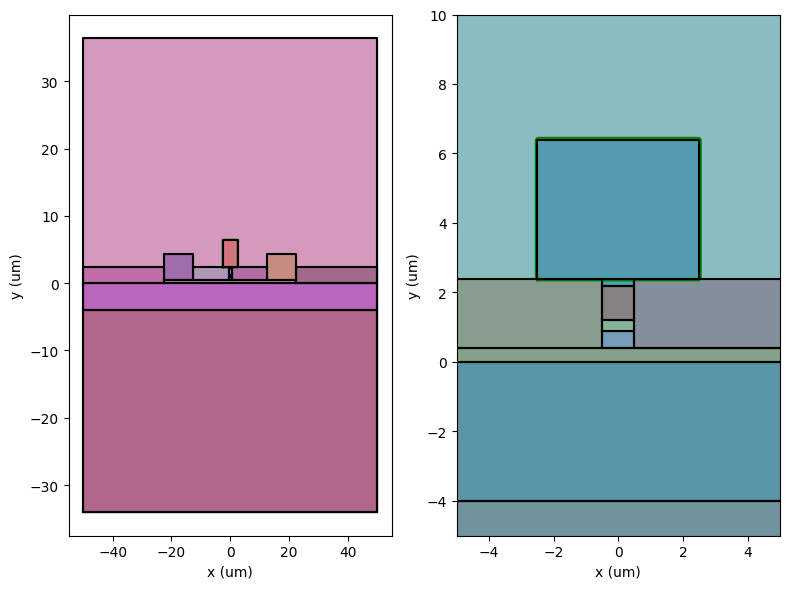

In [2]:
eopm = InP_EOPM()
eopm._make_meshes()
eopm._create_polygons()
eopm._initialize_device()

fig = plt.figure(figsize=(8, 6))
gs = fig.add_gridspec(1, 2)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])

for ax in [ax1, ax2]:
    eopm.device.plot_polygons(
        color_polygon="black",
        color_line="green",
        color_junctions="blue",
        fill_polygons=True,
        fig=fig,
        ax=ax,
    )

ax2.set_xlim(-5, 5)
ax2.set_ylim(-5, 10)

ax1.set_xlabel("x (um)")
ax1.set_ylabel("y (um)")
ax2.set_xlabel("x (um)")
ax2.set_ylabel("y (um)")

plt.tight_layout()
plt.show()

## Find the optical mode with Lumerical MODE

Instead of femwell, we solve the optical modes with the finite-difference eigenmode (FDE) solver of Lumerical MODE, through `OpticalSimulatorMODE`. The workflow is:

1. `OpticalSimulatorMODE(...)` opens a MODE session and creates one polygon and one (n,k) material per device polygon. The index is evaluated from each polygon's `optical_material` at `wavelength` (in µm).
2. `create_fde(...)` adds the FDE solver. Its region is the `simulation_window`, and `dx`/`dy` are the maximum mesh steps in metres.
3. `compute_modes()` runs the mode search.
4. `select_modes(...)` picks the TE and TM modes and loads their fields.
5. `transfer_results_to_device()` stores the fields in `eopm.device.mode` for the `ElectroOpticalSimulator`.

The FDE window must cover the window of the `ElectroOpticalSimulator` used later (`shapely.box(-3, -1, 3, 5)`), because the EO overlap integrals sample the mode fields there. We exclude the metals, as in the femwell tutorial.

In [3]:
mode = OpticalSimulatorMODE(
    device=eopm.device,
    simulation_window=shapely.box(-4, -2, 4, 6),
    include_metals=False,
    save_sim=False,
    wavelength=1.55,
    GUI=False,
)

mode.create_fde(num_modes=6, dx=20e-9, dy=10e-9, background_index=3.2)
mode.mode.setnamed("FDE", "wavelength", 1.55e-6)

mode.compute_modes()

List of polygons in simulation:
p2_m
p1_m
wg2_m
wg1_m
n_m
box_m
bcb_left_m
bcb_right_m
bcb_far_left_m
bcb_far_right_m
substrate_m


The results of the mode search are available through the lumapi session in `mode.mode`. We print the effective index, loss and TE polarisation fraction of every mode found:

In [4]:
n_found = int(mode.mode.nummodes())
neffs, losses, te_fractions = [], [], []
for i in range(1, n_found + 1):
    name = f"FDE::data::mode{i}"
    neffs.append(complex(np.squeeze(mode.mode.getresult(name, "neff"))))
    losses.append(float(np.squeeze(mode.mode.getresult(name, "loss"))) * 1e-2)  # dB/m -> dB/cm
    te_fractions.append(float(np.squeeze(mode.mode.getresult(name, "TE polarization fraction"))))
    print(
        f"Mode {i}: neff = {neffs[-1].real:.4f}, loss = {losses[-1]:.2f} dB/cm, "
        f"TE fraction = {te_fractions[-1]:.3f}"
    )

Mode 1: neff = 3.2194, loss = 36505.56 dB/cm, TE fraction = 0.998
Mode 2: neff = 3.2116, loss = 25388.80 dB/cm, TE fraction = 0.002
Mode 3: neff = 3.2096, loss = 4.71 dB/cm, TE fraction = 0.001
Mode 4: neff = 3.2028, loss = 1.86 dB/cm, TE fraction = 0.999


The two modes with the highest effective index are confined in the InGaAs contact layer `p2` on top of the mesa. InGaAs absorbs at 1550 nm, so they have losses of tens of thousands of dB/cm. The modes we want are the low-loss TE and TM modes guided by the `wg1` core.

`select_modes(auto_select=True)` assumes that the fundamental TE and TM modes are modes 1 and 2, which is not the case here. Instead, we pick the lowest-loss TE-like and TM-like modes and pass their (1-based) indices with `TE_TM_idx=[TE, TM]`:

TE and TM mode indexes;



TE mode: 4, TM mode: 3


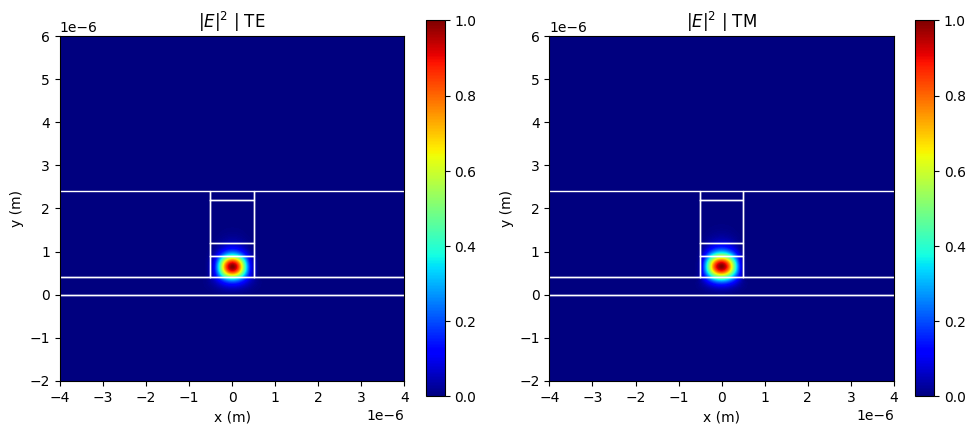

In [5]:
losses = np.array(losses)
te_fractions = np.array(te_fractions)

idx_TE = int(np.argmin(np.where(te_fractions > 0.5, losses, np.inf))) + 1
idx_TM = int(np.argmin(np.where(te_fractions < 0.5, losses, np.inf))) + 1

TE_TM_idx = mode.select_modes(TE_TM_idx=[idx_TE, idx_TM])
print(f"TE mode: {TE_TM_idx[0]}, TM mode: {TE_TM_idx[1]}")

fig, axs = mode.plot_mode(figsize=(10, 5), aspect="equal")
plt.show()

mode.transfer_results_to_device()

## Solve the charge transport equations in 2D

`ChargeSimulatorCHARGE` opens a Lumerical DEVICE session and builds the cross-section in it:

- one CHARGE material and polygon for every semiconductor that has a `doping_type`,
- the two contacts, `bias_contact` and `ground_contact`. Both are names of `MetalPolygon`s of the device and are modelled as ohmic contacts at their interfaces with the semiconductors,
- optionally the insulators (`include_insulators=True`), with the DC permittivity taken from their `rf_eps`. Each insulator is clipped by the polygons above it in the device priority order, so no two CHARGE solids overlap.

CHARGE takes one contact per terminal. We bias the signal metal on top of the p-mesa and ground the left n-contact. In reverse bias almost no current flows, so the second n-contact on the right would not change the solution. If no `simulation_window` is given, the bounding box of all charge semiconductors (here the full 45 µm wide n-layer) is used.

The bias is swept on `sig_metal` from 0 to -6 V, that is, in reverse bias. CHARGE stops a sweep without an error at the first bias point it cannot converge, so we use 0.5 V steps.

In [6]:
charge = ChargeSimulatorCHARGE(
    device=eopm.device,
    bias_start_stop_step=[0, -6, 13],
    bias_contact="sig_metal",
    ground_contact="n_metal_left",
    include_insulators=True,
    filename="dc_2d_electro_optical.ldev",
    GUI=False,
)

print(f"Simulation window bounds (um): {charge.simulation_window.bounds}")

Charge transport will take place with:
p2
p1
wg2
wg1
n


D:\Repos\Imodulator\.venv\Lib\site-packages\pint\facets\numpy\numpy_func.py:324: RuntimeWarning: invalid value encountered in log
  result_magnitude = func(*stripped_args, **stripped_kwargs)


Simulation window bounds (um): (-22.6, -0.1, 22.6, 2.5)


The material parameters passed to CHARGE are stored in `charge.materials`, which is useful to check what each layer looks like to the solver:

In [7]:
import pandas as pd

pd.DataFrame(charge.materials).T

,Eg,affinity,work_function,mn,mp,eps_dc,mun,mup,doping_type,doping_conc
p2,0.732712,4.520518,4.886874,0.038262,0.476708,13.801568,14049.563195,80.89861,p,10000000000000000000.0
p1,1.352886,4.247114,4.923557,0.075169,0.641681,12.3,5199.999999,126.385498,p,100000000000000000.0
wg2,1.352886,4.247114,4.923557,0.075169,0.641681,12.3,4392.723599,170.0,n,10000000000000000.0
wg1,0.990406,4.451748,4.946951,0.053731,0.507646,13.124632,4318.803121,110.179972,n,10000000000000000.0
n,1.352886,4.247114,4.923557,0.075169,0.641681,12.3,2138.516745,170.0,n,1000000000000000000.0


`create_charge` adds the simulation region, the CHARGE solver, the mesh constraints, the contacts with the bias sweep, and the doping. Its mesh controls are in metres:

- `mesh_semiconductor`: maximum triangle edge inside every semiconductor,
- `mesh_max`: maximum edge everywhere else,
- `min_edge_length`: the CHARGE mesher refines every abrupt doping step down to this length, which resolves the depletion edges. This refinement, more than `mesh_semiconductor`, sets the element count.

The defaults (20 nm / 200 nm / 5 nm) keep the field in the intrinsic layers within about 1 % of a much finer mesh. Accumulation layers at heterojunctions, which are a few nm thick, need `min_edge_length` of 1-2 nm. The runtime is set mostly by the voltage span of the sweep.

In [8]:
charge.create_charge(
    mesh_semiconductor=20e-9,
    mesh_max=200e-9,
    min_edge_length=5e-9,
    solver_type="newton",
)

charge.solve()

print(f"Converged bias points (V): {charge.V}")

Converged bias points (V): [ 0.  -0.5 -1.  -1.5 -2.  -2.5 -3.  -3.5 -4.  -4.5 -5.  -5.5 -6. ]


### 2D results

`plot_results` shows the electron and hole densities and the field magnitude at one bias point. Zooming in on the mesa:

- at 0 V the built-in field depletes `wg2` (the thin InP layer between the core and `p1`), while the `wg1` core is still filled with electrons,
- in reverse bias the depletion region grows down through `wg1`, and at -6 V only a thin electron layer is left at the bottom of the core. The field is strongest at the `wg2`/`p1` junction,
- the field also fringes out of the mesa into the BCB on both sides, and peaks at the corners where the junction meets the sidewalls. A 1D solve misses this.

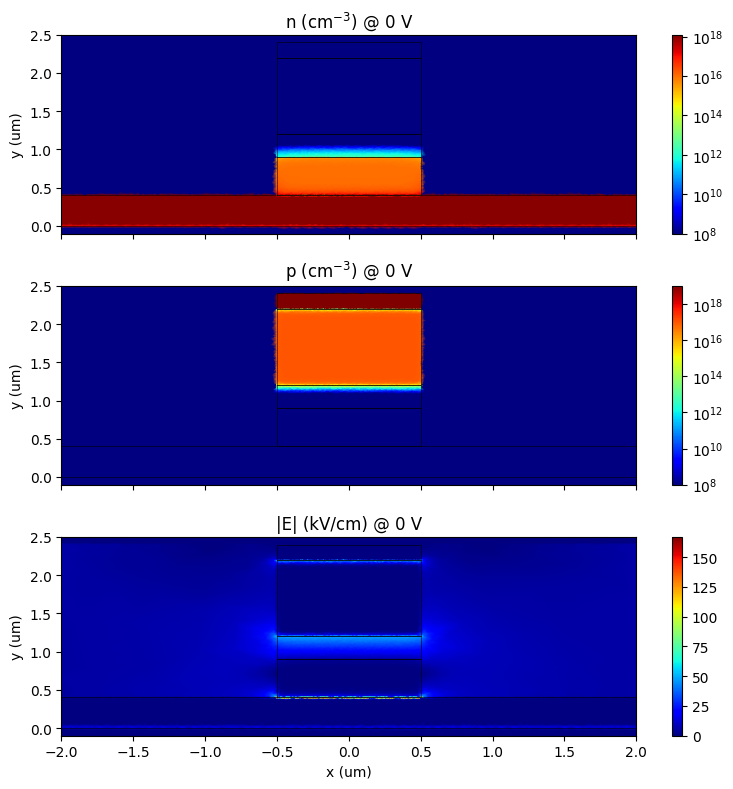

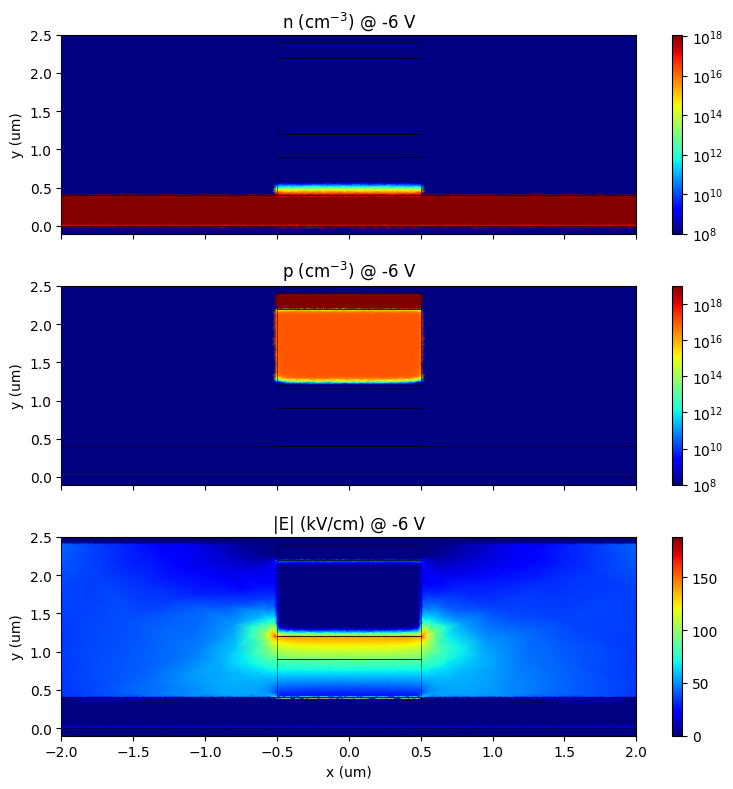

In [9]:
for V_idx in (0, -1):
    fig, axs = charge.plot_results(V_idx=V_idx, figsize=(8, 8), xlim=(-2, 2), ylim=(-0.1, 2.5))
    plt.show()

The full cross-section at the highest reverse bias shows that the n-layer stays neutral all the way to the grounded contact on the left, so the full bias drops across the mesa. Outside the mesa the field is concentrated at the edges of the signal metal on top of the BCB:

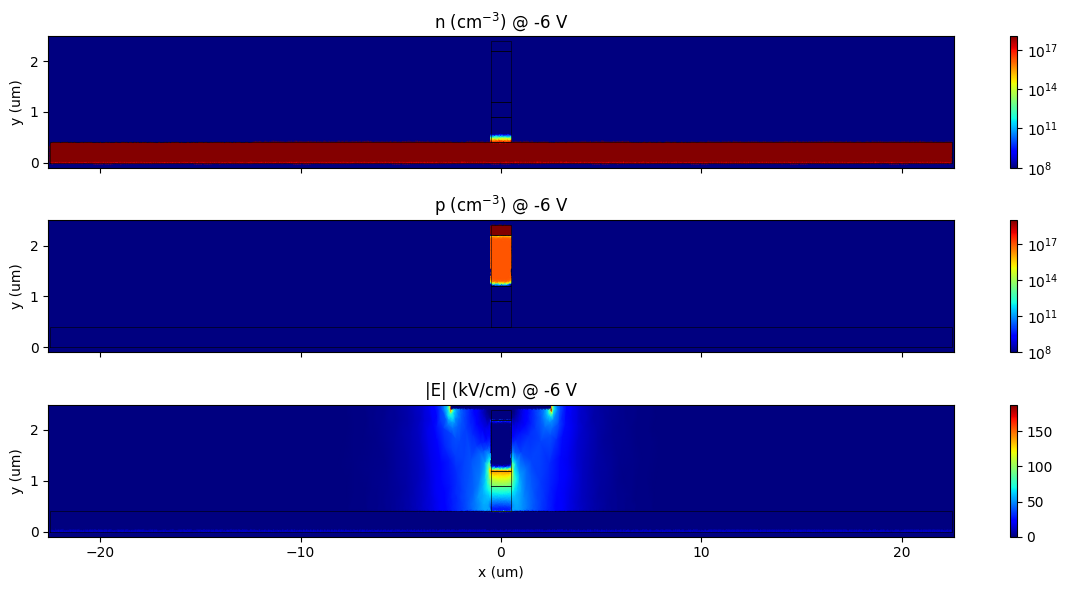

In [10]:
fig, axs = charge.plot_results(V_idx=-1, figsize=(12, 6))
plt.show()

### Cuts along a line

`get_line_profile` samples the 2D solution along a `LineString`, in the same units as the 1D solvers. A vertical cut through the centre of the waveguide gives the band diagram, carrier densities and field we would get from the 1D tutorial. `Efield` is the field component along the direction of the line.

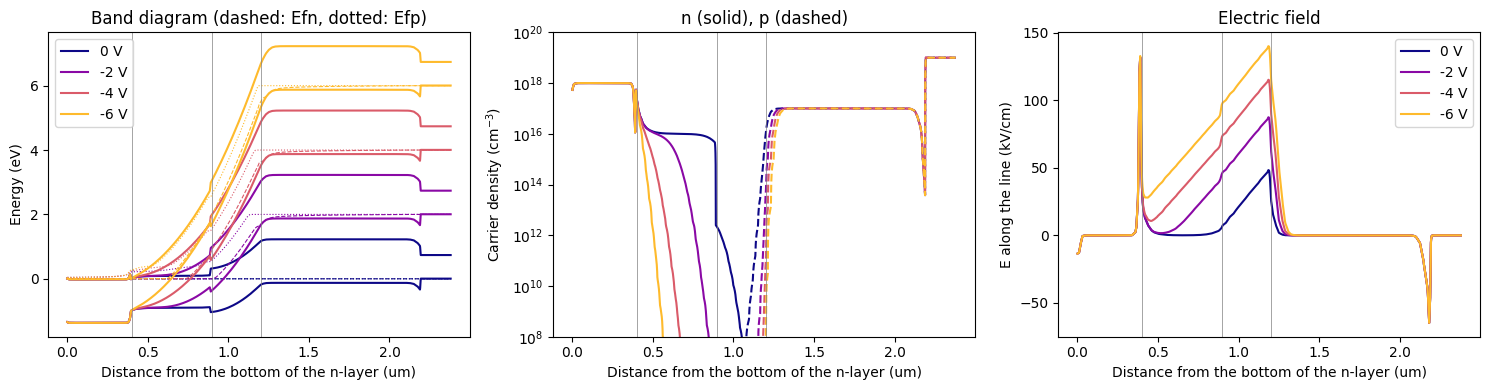

In [11]:
h_total = eopm.h_n + eopm.h_wg1 + eopm.h_wg2 + eopm.h_p1 + eopm.h_p2
line = shapely.LineString([[0, 0.01], [0, h_total - 0.01]])

profile = charge.get_line_profile(line)

V_idxs = [0, 4, 8, 12]
colors = plt.cm.plasma(np.linspace(0, 0.85, len(V_idxs)))

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for k, color in zip(V_idxs, colors):
    label = f"{profile['V'][k]:g} V"
    axs[0].plot(profile["s"], profile["Ec"][k], color=color, label=label)
    axs[0].plot(profile["s"], profile["Ev"][k], color=color)
    axs[0].plot(profile["s"], profile["Efn"][k], color=color, ls="--", lw=0.8)
    axs[0].plot(profile["s"], profile["Efp"][k], color=color, ls=":", lw=0.8)
    axs[1].semilogy(profile["s"], profile["N"][k], color=color, label=f"n, {label}")
    axs[1].semilogy(profile["s"], profile["P"][k], color=color, ls="--")
    axs[2].plot(profile["s"], profile["Efield"][k], color=color, label=label)

axs[0].set_ylabel("Energy (eV)")
axs[0].set_title("Band diagram (dashed: Efn, dotted: Efp)")
axs[1].set_ylabel("Carrier density (cm$^{-3}$)")
axs[1].set_ylim(1e8, 1e20)
axs[1].set_title("n (solid), p (dashed)")
axs[2].set_ylabel("E along the line (kV/cm)")
axs[2].set_title("Electric field")
for ax in axs:
    ax.set_xlabel("Distance from the bottom of the n-layer (um)")
    for y in np.cumsum([eopm.h_n, eopm.h_wg1, eopm.h_wg2, eopm.h_p1])[:-1]:
        ax.axvline(y, color="gray", lw=0.5)
axs[0].legend()
axs[2].legend()
fig.tight_layout()
plt.show()

A horizontal cut through the middle of `wg1`, the optical core, tells us how good a 1D solve would be for this device. Across the core the vertical field is nearly uniform and only rises slightly at the sidewalls. For a deep-etched 1 µm wide waveguide the 1D approximation therefore holds well inside the core. The 2D solve matters more for narrower or shallow-etched waveguides and for lateral junctions.

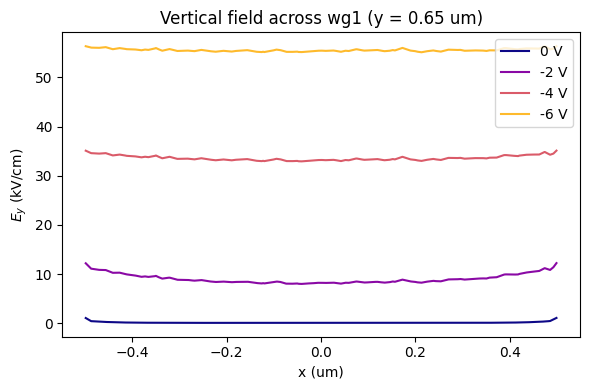

In [12]:
y_mid = eopm.h_n + eopm.h_wg1 / 2
hline = shapely.LineString([[-eopm.w_wg / 2 + 0.001, y_mid], [eopm.w_wg / 2 - 0.001, y_mid]])
hprofile = charge.get_line_profile(hline)

# the y component of the field, interpolated from the 2D CHARGE solution
from matplotlib.tri import LinearTriInterpolator, Triangulation

e = charge.results["electrostatics"]
tri = Triangulation(e["x"], e["y"], e["connectivity"])
fig, ax = plt.subplots(figsize=(6, 4))
for k, color in zip(V_idxs, colors):
    Ey = LinearTriInterpolator(tri, e["Ey"][k])(hprofile["x"], hprofile["y"])
    ax.plot(hprofile["x"], Ey, color=color, label=f"{hprofile['V'][k]:g} V")
ax.set_xlabel("x (um)")
ax.set_ylabel("$E_y$ (kV/cm)")
ax.set_title(f"Vertical field across wg1 (y = {y_mid:.2f} um)")
ax.legend()
fig.tight_layout()
plt.show()

Finally, the current through the grounded contact. In reverse bias it is the leakage current of the junction, normalised to the CHARGE `norm length` (1 cm by default). The 0 V point is left out, since the current there is zero up to numerical noise:

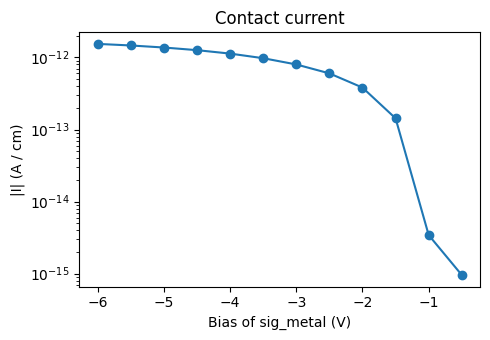

In [13]:
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.semilogy(charge.V[1:], np.abs(charge.I["n_metal_left"][1:]), marker="o")
ax.set_xlabel("Bias of sig_metal (V)")
ax.set_ylabel("|I| (A / cm)")
ax.set_title("Contact current")
fig.tight_layout()
plt.show()

### Transfer the results to the device

`transfer_results_to_device` stores 2D interpolators in `eopm.device.charge`, with the same keys and units as the 1D solvers. The `ElectroOpticalSimulator` cannot tell the two apart. Unlike the 1D case, the electric field is now a full vector $(E_x, E_y, 0)$, so the lateral field near the sidewalls also enters the Pockels and Kerr terms.

In [14]:
charge.transfer_results_to_device()

print(eopm.device.charge.keys())

dict_keys(['Ec', 'Ev', 'Efn', 'Efp', 'N', 'P', 'Efield', 'mun', 'mup', 'V'])


## Calculate the electro optic response

From here on everything is identical to the 1D tutorial. We mesh the EO simulation window and compute $\Delta \bar{\epsilon}(x,y,V)$ for every bias point:

Text(0, 0.5, 'y (um)')

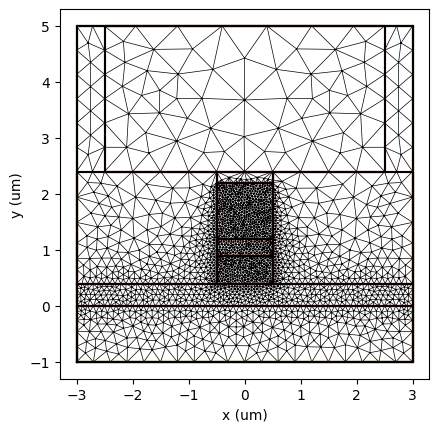

In [15]:
EO = ElectroOpticalSimulator(device=eopm.device, simulation_window=shapely.box(-3, -1, 3, 5))

EO.make_mesh()

fig, ax = EO.plot_mesh()
EO.plot_polygons(ax=ax)

ax.set_xlabel("x (um)")
ax.set_ylabel("y (um)")

In [16]:
EO.get_epsilon_optical()

print(EO.epsilon_optical["InGaAsPElectroOpticalModel"]["dperms"].shape)
print(EO.epsilon_optical["InGaAsPElectroOpticalModel"]["labels"])

D:\Repos\Imodulator\.venv\Lib\site-packages\pint\facets\numpy\numpy_func.py:324: RuntimeWarning: invalid value encountered in sqrt
  result_magnitude = func(*stripped_args, **stripped_kwargs)
D:\Repos\Imodulator\.venv\Lib\site-packages\pint\facets\numpy\numpy_func.py:324: RuntimeWarning: overflow encountered in exp
  result_magnitude = func(*stripped_args, **stripped_kwargs)


D:\Repos\Imodulator\.venv\Lib\site-packages\pint\facets\numpy\numpy_func.py:324: RuntimeWarning: invalid value encountered in log
  result_magnitude = func(*stripped_args, **stripped_kwargs)
D:\Repos\Imodulator\.venv\Lib\site-packages\pint\facets\plain\quantity.py:1296: RuntimeWarning: invalid value encountered in power
  magnitude = new_self._magnitude**exponent
D:\Repos\Imodulator\.venv\Lib\site-packages\pint\facets\plain\quantity.py:1296: RuntimeWarning: invalid value encountered in sqrt
  magnitude = new_self._magnitude**exponent


(3, 3, 2247, 13, 5)
['Bandfilling', 'Plasma', 'Intervalence', 'Pockels', 'Kerr']


The real part of the change in permittivity (electro-refraction) for each effect, between 0 V and the highest reverse bias. The charge effects (band filling, plasma, intervalence) sit where carriers are swept out: the electrons in `wg1` and the holes at the edge of `p1`. The field effects (Pockels, Kerr) fill the depleted layers. All of them follow the 2D CHARGE solution, including at the sidewalls:

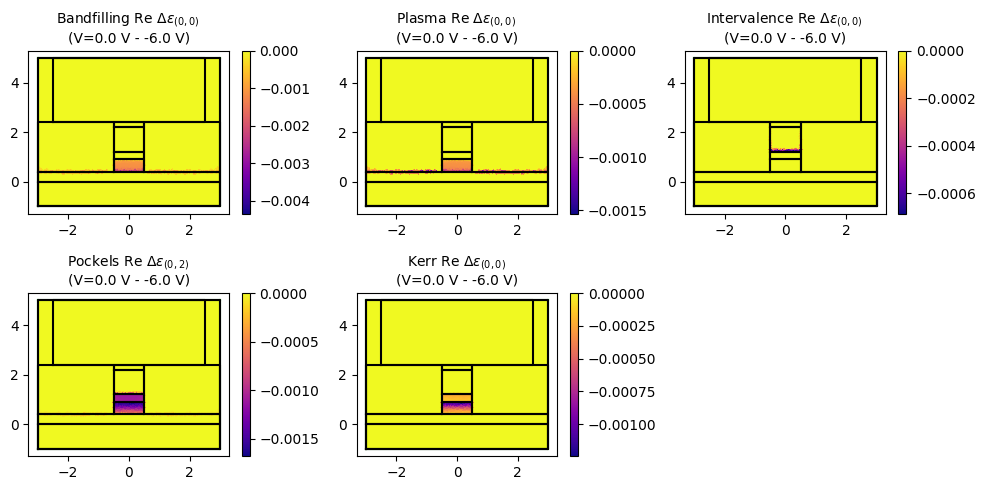

In [17]:
# Here we will inspect some of the calculated properties
# We know we are working with InGaAsP materials so we'll focus on those ElectroOpticalModel properties

V_values = list(eopm.device.charge["V"])
idx_voltage1 = -1
idx_voltage2 = 0

fig = plt.figure(figsize=(10, 5))
gs = fig.add_gridspec(2, 3)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[0, 2])
ax4 = fig.add_subplot(gs[1, 0])
ax5 = fig.add_subplot(gs[1, 1])

axes = [ax1, ax2, ax3, ax4, ax5]

tensor_elements = [(0, 0), (0, 0), (0, 0), (0, 2), (0, 0)]

for idx_effect in range(5):
    e11, e22 = tensor_elements[idx_effect]
    eps1 = EO.epsilon_optical["InGaAsPElectroOpticalModel"]["dperms"][
        e11, e22, :, idx_voltage1, idx_effect
    ]
    eps2 = EO.epsilon_optical["InGaAsPElectroOpticalModel"]["dperms"][
        e11, e22, :, idx_voltage2, idx_effect
    ]
    label = EO.epsilon_optical["InGaAsPElectroOpticalModel"]["labels"][idx_effect]

    ax = axes[idx_effect]

    EO.basis.plot((eps2 - eps1).real, ax=ax, cmap="plasma", colorbar=True)
    # scat= ax.scatter(
    #     EO.mesh.p[0],
    #     EO.mesh.p[1],
    #     c=(eps2 - eps1).imag,
    # )
    # fig.colorbar(scat, ax=ax, label=f'Imaginary part of $\\Delta \\epsilon_{{{e11,e22}}}$')
    ax.set_title(
        f"{label} Re $\\Delta\\epsilon_{{{e11, e22}}}$ \n(V={V_values[idx_voltage2]} V - {V_values[idx_voltage1]} V)",
        fontsize=10,
    )

    EO.plot_polygons(fig=fig, ax=ax)


fig.tight_layout()

Finally, the phase and amplitude response from the overlap with the optical modes. As in the 1D tutorial we rotate the permittivity by 45° around the y axis, so that the Pockels contribution is positive, and take 0 V as reference:

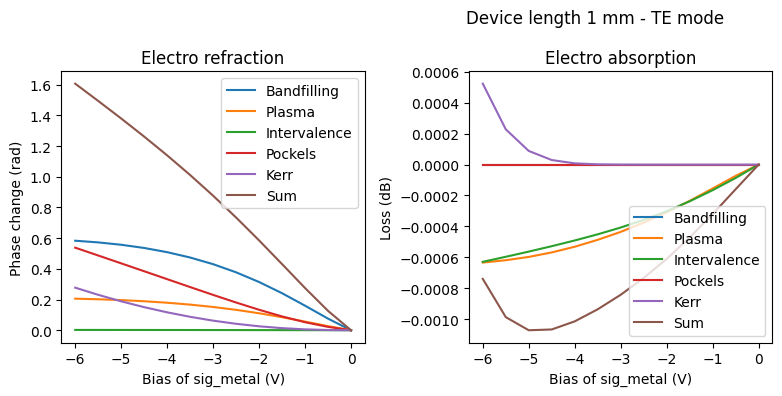

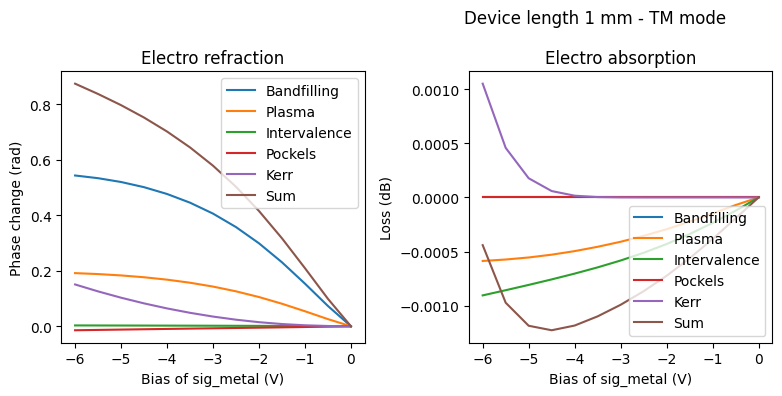

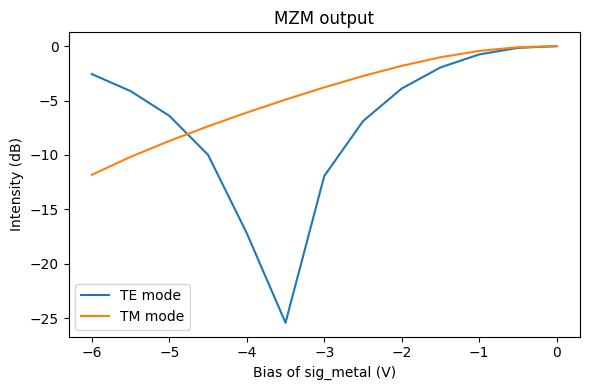

In [18]:
V_values = list(eopm.device.charge["V"])

# Calculate the EO response for all voltages
all_res_TE = []
all_res_TM = []

for i in range(len(eopm.device.charge["V"])):
    kappa_aa = EO.calculate_EO_response(
        voltage_idx=i,
        rot_x=0,
        rot_y=np.pi / 4,
        rot_z=0,
        base_epsilon_voltage_idx=0,
        optical_mode_a="TE",
        optical_mode_b="TE",
    )

    kappa_bb = EO.calculate_EO_response(
        voltage_idx=i,
        rot_x=0,
        rot_y=np.pi / 4,
        rot_z=0,
        base_epsilon_voltage_idx=0,
        optical_mode_a="TM",
        optical_mode_b="TM",
    )

    ## Adjust to have phase change

    all_res_TE.append(kappa_aa["InGaAsPElectroOpticalModel"]["results"])
    all_res_TM.append(kappa_bb["InGaAsPElectroOpticalModel"]["results"])
    # print(res['InGaAsPElectroOpticalModel']['results'].real*1e-3)
all_res_TE = np.asarray(all_res_TE)
all_res_TM = np.asarray(all_res_TM)

for all_res, title in zip([all_res_TE, all_res_TM], ["TE", "TM"]):
    fig = plt.figure(figsize=(12, 4))

    gs = fig.add_gridspec(1, 3)
    ax1 = fig.add_subplot(gs[0, 0])
    ax2 = fig.add_subplot(gs[0, 1])

    for i in range(5):
        ax1.plot(
            V_values,
            np.real(all_res[:, i] * 1e-3),
            label=f"{kappa_aa['InGaAsPElectroOpticalModel']['labels'][i]}",
        )

    ax1.plot(V_values, np.sum(np.real(all_res), axis=1) * 1e-3, label="Sum")
    ax1.legend()
    ax1.set_xlabel("Bias of sig_metal (V)")
    ax1.set_ylabel("Phase change (rad)")
    ax1.set_title("Electro refraction")

    for i in range(5):
        conversion_factor = 20 * np.log10(np.e)  # about 8.686
        ax2.plot(
            V_values,
            np.imag(all_res[:, i] * 1e-3) * conversion_factor,
            label=f"{kappa_aa['InGaAsPElectroOpticalModel']['labels'][i]}",
        )

    ax2.plot(V_values, np.sum(np.imag(all_res) * 1e-3, axis=1) * conversion_factor, label="Sum")
    ax2.legend()
    ax2.set_xlabel("Bias of sig_metal (V)")
    ax2.set_ylabel("Loss (dB)")
    ax2.set_title("Electro absorption")

    fig.suptitle(f"Device length 1 mm - {title} mode")
    fig.tight_layout()

fig = plt.figure(figsize=(6, 4))
ax3 = fig.add_subplot(1, 1, 1)

for all_res, title in zip([all_res_TE, all_res_TM], ["TE", "TM"]):
    Eout = 1 / 2 * (1 + np.exp(1j * np.sum(all_res * 3e-3, axis=1)))
    Iout = np.abs(Eout) ** 2

    ax3.plot(V_values, 10 * np.log10(Iout), label=f"{title} mode")
ax3.set_xlabel("Bias of sig_metal (V)")
ax3.set_ylabel("Intensity (dB)")
ax3.set_title("MZM output")
ax3.legend()

fig.tight_layout()

The trends match the 1D tutorial: the charge effects contribute significantly, the intervalence term gives a small gain as holes are depleted from the p-side, and TE and TM have very different $V_\pi$ because of the Pockels effect.

For this deep-etched waveguide the field in the core is nearly uniform across its width, so the 2D solve mostly confirms the 1D picture. The differences are near the sidewalls, where the field fringes and the lateral component $E_x$ adds to the Pockels and Kerr contributions. Two other things differ from the 1D tutorial: the modes come from a finite-difference solver instead of a finite-element one, and the CHARGE materials use constant mobilities. To quantify the difference for your own device, compare `charge.get_line_profile` with the result of `ChargeSimulatorSolcore` along the same line.

Note that the bias here is applied to the p-contact, so reverse bias is negative. In the 1D Solcore tutorial it is positive.